In [59]:
from google.colab import drive
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. 구글 드라이브 마운트 (실행 시 계정 권한 허용 창이 뜹니다)
drive.mount('/content/drive')

# 2. 파일 경로 지정
# 드라이브 최상단(내 드라이브)에 파일이 있을 경우의 경로입니다.
# 만약 특정 폴더 안에 넣으셨다면 경로를 수정해 주세요.
# 예: '/content/drive/MyDrive/데이터분석/신한카드_빅콘테스트2026_데이터1.txt'
file_path = '/content/drive/MyDrive/capston/신한카드_빅콘테스트2026_데이터1.txt'

# 3. 데이터 불러오기
# 인코딩 옵션을 추가해서 다시 불러오기
df = pd.read_csv(file_path, sep='\t', encoding='cp949')

# 데이터가 잘 불러와졌는지 상위 5개 행 확인
display(df.head())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,TA_YMD,TIME_GB,MCT_SGG_CD,MCT_RY_CD,SEX_CCD,AGE_CCD,TS_AT,USE_CNT
0,20250704,12_17,서울 강남구,가구,법인,법인,15477163,16
1,20250721,12_17,서울 강남구,가구,법인,법인,308451,38
2,20250703,12_17,서울 강남구,가구,여성,20 대,78970,5
3,20250703,18_23,서울 강남구,가구,남성,20 대,271220,5
4,20250706,18_23,서울 강남구,가구,여성,20 대,260872,5


In [60]:
# 1. 코랩에 나눔 폰트 설치 (설치 과정 출력 숨김)
!apt-get -qq -y install fonts-nanum > /dev/null

from google.colab import drive
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.font_manager as fm

# 2. 폰트 강제 적용
fontpath = '/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf'
fm.fontManager.addfont(fontpath)
mpl.rc('font', family='NanumBarunGothic')
mpl.rc('axes', unicode_minus=False)

# 3. 구글 드라이브 마운트
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [61]:
# 4. 데이터 불러오기 (본인의 파일 경로에 맞게 수정 필요)
file_path = '/content/drive/MyDrive/capston/신한카드_빅콘테스트2026_데이터1.txt'
df = pd.read_csv(file_path, sep='\t', encoding='cp949')

# 5. 그룹별(지역, 성별, 연령), 카테고리별 소비 건수 집계
group_cols = ['MCT_SGG_CD', 'SEX_CCD', 'AGE_CCD']
category_counts = df.groupby(group_cols + ['MCT_RY_CD'])['USE_CNT'].sum().reset_index()

# 6. 그룹별 총 소비 건수 계산 및 카테고리별 비중(%) 산출
total_counts = category_counts.groupby(group_cols)['USE_CNT'].sum().reset_index()
total_counts.rename(columns={'USE_CNT': 'TOTAL_CNT'}, inplace=True)

# 7. 데이터를 병합하여 비율 계산
merged_df = pd.merge(category_counts, total_counts, on=group_cols)
merged_df['CATEGORY_RATIO(%)'] = (merged_df['USE_CNT'] / merged_df['TOTAL_CNT']) * 100

# 8. 피벗 테이블 생성 (행: 인구통계 그룹, 열: 소비 카테고리)
pivot_df = merged_df.pivot_table(
    index=group_cols,
    columns='MCT_RY_CD',
    values='CATEGORY_RATIO(%)',
    fill_value=0
)

# 데이터가 잘 만들어졌는지 상위 5개 그룹 확인
display(pivot_df.head())

MCT_RY_CD                      LPG가스    ZZ_나머지        가구        가전   게임방/오락실  \
MCT_SGG_CD SEX_CCD AGE_CCD                                                     
강원 춘천시     남성      10 대     0.031750  5.839912  0.000000  0.006623  8.570243   
                   20 대     0.209893  4.152740  0.014005  0.020891  5.376735   
                   30 대     0.342362  3.173819  0.035207  0.059341  1.372482   
                   40 대     0.817854  2.600874  0.044316  0.086117  0.352400   
                   50 대     2.139373  2.060293  0.027534  0.118135  0.358794   

MCT_RY_CD                   결제대행(PG)  고속버스/철도/여객선      기타식품      기타요식  \
MCT_SGG_CD SEX_CCD AGE_CCD                                              
강원 춘천시     남성      10 대          0.0     0.000000  6.651785  7.249197   
                   20 대          0.0     0.004318  4.021860  9.034294   
                   30 대          0.0     0.009245  4.165967  8.280887   
                   40 대          0.0     0.017817  4.068517  6.900056   
                   50 대          0.0     0.028079  3.761349  6.882147   

MCT_RY_CD                       기타유통  ...     학교등록금    학원/학습지         한식  \
MCT_SGG_CD SEX_CCD AGE_CCD            ...                                  
강원 춘천시     남성      10 대     0.052203  ...  0.001169  0.020063   6.093720   
                   20 대     0.092995  ...  0.000257  0.021008   8.388835   
                   30 대     0.111734  ...  0.000156  0.075803   9.793532   
                   40 대     0.177481  ...  0.000422  0.418202  11.570986   
                   50 대     0.307249  ...  0.008151  0.194713  14.388475   

MCT_RY_CD                        한의원  할인점/슈퍼마켓/양판점       헬스장     호텔/콘도  \
MCT_SGG_CD SEX_CCD AGE_CCD                                               
강원 춘천시     남성      10 대     0.032140      4.859744  0.077330  0.162842   
                   20 대     0.076259      6.652129  0.247381  0.104690   
                   30 대     0.162411      9.965387  0.210876  0.138533   
                   40 대     0.199904     13.099216  0.202793  0.266565   
                   50 대     0.289227     13.451856  0.172063  0.151846   

MCT_RY_CD                         화원       화장품  회계/변리서비스  
MCT_SGG_CD SEX_CCD AGE_CCD                                
강원 춘천시     남성      10 대     0.038568  0.010519  0.001169  
                   20 대     0.109218  0.024766  0.012418  
                   30 대     0.159589  0.033492  0.018717  
                   40 대     0.130885  0.029622  0.018535  
                   50 대     0.151352  0.032656  0.011197  

[5 rows x 91 columns]

In [62]:
# 1. 누락 데이터 0개! 완벽 반영된 세분화 대분류 사전
category_map_final = {
    # 🚨 [핵심] 사회적 고립 & 1인 은둔형 소비 지표 (가장 중요)
    '편의점': '고립/1인 (편의점/마트)',
    '할인점/슈퍼마켓/양판점': '고립/1인 (편의점/마트)',
    '패스트푸드': '고립/1인 (패스트푸드)',
    '결제대행(PG)': '고립/은둔 (배달/온라인PG)',
    '게임방/오락실': '고립/은둔 (게임/오락)',
    '주류판매': '고립/이상소비 (주류/유흥)',
    '유흥업소': '고립/이상소비 (주류/유흥)',
    '상품권/복권': '고립/이상소비 (복권/상품권)',

    # 외식 / 다이닝 (외부 사회활동)
    '양식': '외식/사교', '일식': '외식/사교', '중식': '외식/사교', '한식': '외식/사교',
    '체인점': '외식/사교', '기타요식': '외식/사교', '커피전문점': '외식/사교',

    # 식재료 / 요리 (다인 가구 특성)
    '농수산물': '식생활/식재료', '정육점': '식생활/식재료', '제과점': '식생활/식재료', '기타식품': '식생활/식재료',

    # 외부 여가 / 문화 / 여행 (사회적 교류 지표)
    '노래방': '외부 여가/문화', '영화/공연': '외부 여가/문화', '스포츠시설': '외부 여가/문화',
    '실내/실외골프장': '외부 여가/문화', '종합레저타운/놀이동산': '외부 여가/문화',
    '여행사/항공사': '외부 여가/문화', '호텔/콘도': '외부 여가/문화', '모텔,여관,기타숙박': '외부 여가/문화',

    # 교육 / 자기계발
    '서점': '교육/학습', '문화용품': '교육/학습', '독서실': '교육/학습', '유치원': '교육/학습',
    '학원/학습지': '교육/학습', '학교등록금': '교육/학습',

    # 의료 / 건강 관리
    '약국': '의료/건강', '일반병원': '의료/건강', '한의원': '의료/건강', '보건소': '의료/건강',
    '기타의료': '의료/건강', '종합병원': '의료/건강', '치과병원': '의료/건강',

    # 뷰티 / 미용 / 자기관리
    '미용실': '뷰티/자기관리', '화장품': '뷰티/자기관리', '미용서비스': '뷰티/자기관리',
    '안마/마사지': '뷰티/자기관리', '싸우나/목욕탕': '뷰티/자기관리',

    # 쇼핑 / 유통 / 물품 구매
    '가전': '쇼핑/유통', '가구': '쇼핑/유통', '백화점': '쇼핑/유통', '면세점': '쇼핑/유통',
    '쇼핑몰': '쇼핑/유통', '전용매장': '쇼핑/유통', '기타유통': '쇼핑/유통', '패션잡화': '쇼핑/유통',
    '의복/의류': '쇼핑/유통', '시계/귀금속': '쇼핑/유통', '수제용품점': '쇼핑/유통',
    '인테리어/건축자재/주방기구': '쇼핑/유통', '생활잡화/수입상품점': '쇼핑/유통',
    '사무기기/문구용품': '쇼핑/유통', '컴퓨터/소프트웨어': '쇼핑/유통', '악기/음반': '쇼핑/유통',
    '완구/아동용자전거': '쇼핑/유통', '중고품판매점': '쇼핑/유통', '스포츠/레저용품': '쇼핑/유통',

    # 생활 / 필수 서비스 및 공과금
    '세탁소': '생활/필수지출', '화원': '생활/필수지출', '보험': '생활/필수지출',
    '세금공과금': '생활/필수지출', '부동산중개': '생활/필수지출', '법률/사무서비스': '생활/필수지출',
    '회계/변리서비스': '생활/필수지출', '연구/번역서비스': '생활/필수지출',
    '통신요금(이동,시내전화)': '생활/필수지출', '통신요금(PC통신,무선호출)': '생활/필수지출',

    # 교통 / 자동차
    '택시': '교통/차량', '주유소': '교통/차량', '주차장': '교통/차량', 'LPG가스': '교통/차량',
    '오토바이': '교통/차량', '수입자동차': '교통/차량', '자동차용품': '교통/차량',
    '자동차서비스': '교통/차량', '중고차판매': '교통/차량', '고속버스/철도/여객선': '교통/차량',

    # 반려동물 및 기타
    '동물병원': '반려동물/운동', '애완동물': '반려동물/운동', '헬스장': '반려동물/운동',
    '예식장/결혼서비스': '기타(경조사 등)', '장례식장/묘지/장의사': '기타(경조사 등)',
    '방문판매/다단계판매': '기타(경조사 등)', 'ZZ_나머지': '기타(경조사 등)'
}

# 2. 대분류 매핑 덮어씌우기
df['MACRO_CATEGORY'] = df['MCT_RY_CD'].map(category_map_final)

# 3. 누락 점검 (아무것도 안 나오면 완벽함)
missing_cats = df[df['MACRO_CATEGORY'].isnull()]['MCT_RY_CD'].unique()
if len(missing_cats) > 0:
    print("🚨 매핑 누락 데이터:", missing_cats)
else:
    print("✅ 모든 카테고리 매핑 완료! 누락 없음.")

# 4. 피벗 테이블 굽기
group_cols = ['MCT_SGG_CD', 'SEX_CCD', 'AGE_CCD']
category_counts = df.groupby(group_cols + ['MACRO_CATEGORY'])['USE_CNT'].sum().reset_index()

total_counts = category_counts.groupby(group_cols)['USE_CNT'].sum().reset_index()
total_counts.rename(columns={'USE_CNT': 'TOTAL_CNT'}, inplace=True)

merged_df = pd.merge(category_counts, total_counts, on=group_cols)
merged_df['CATEGORY_RATIO(%)'] = (merged_df['USE_CNT'] / merged_df['TOTAL_CNT']) * 100

pivot_df = merged_df.pivot_table(
    index=group_cols,
    columns='MACRO_CATEGORY',
    values='CATEGORY_RATIO(%)',
    fill_value=0
)

✅ 모든 카테고리 매핑 완료! 누락 없음.


In [63]:
# 성별과 연령대를 입력하면 알아서 그래프를 그려주는 함수 정의
def plot_demographic_heatmap(age_group, gender, cmap_color):
    try:
        # 특정 성별과 연령대만 필터링 (결과 행은 '지역'만 남음)
        target_df = pivot_df.xs((gender, age_group), level=('SEX_CCD', 'AGE_CCD'))

        plt.figure(figsize=(14, 5))
        # 40개가 넘던 카테고리를 압축했으므로, 비율을 직접 숫자(annot=True)로 표시합니다.
        sns.heatmap(target_df, cmap=cmap_color, annot=True, fmt=".1f", linewidths=.5)
        plt.title(f'[{age_group} {gender}] 지역별 소비 카테고리 비중 (%)', fontsize=16, pad=15)
        plt.ylabel('지역', fontsize=12)
        plt.xlabel('대분류 카테고리', fontsize=12)
        plt.xticks(rotation=45, ha='right', fontsize=11)
        plt.tight_layout()
        plt.show()
    except KeyError:
        print(f"데이터에 {age_group} {gender} 그룹이 존재하지 않거나 데이터가 부족합니다.")

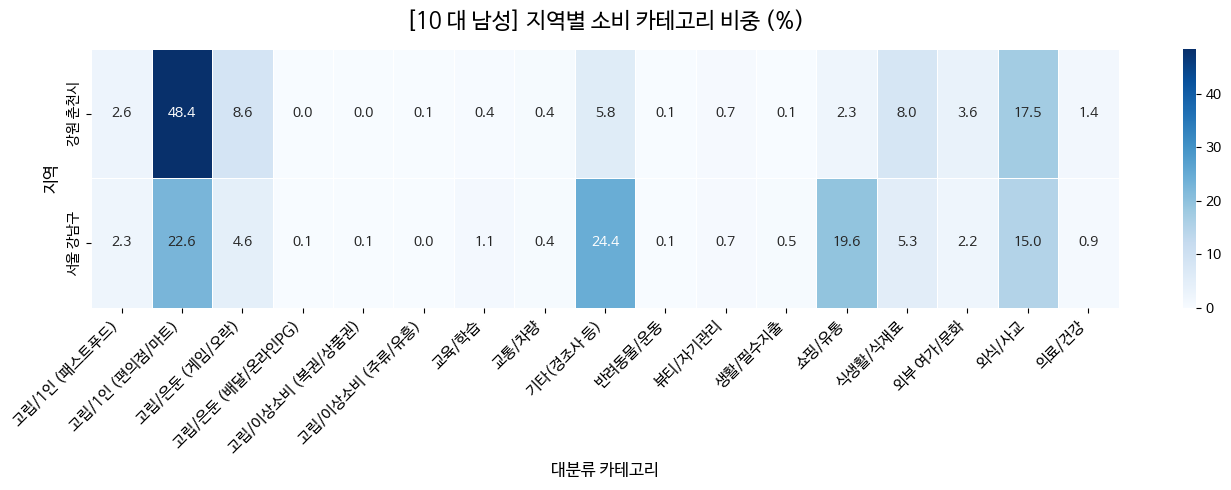

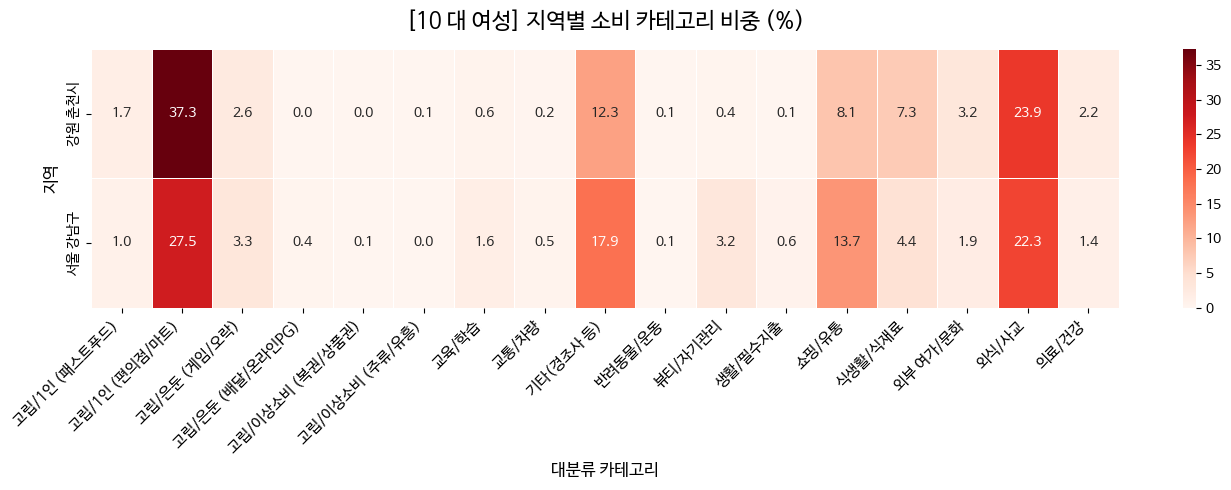

In [64]:
# 10대 남성, 10대 여성 (파란색, 빨간색 계열)
plot_demographic_heatmap('10 대', '남성', 'Blues')
plot_demographic_heatmap('10 대', '여성', 'Reds')

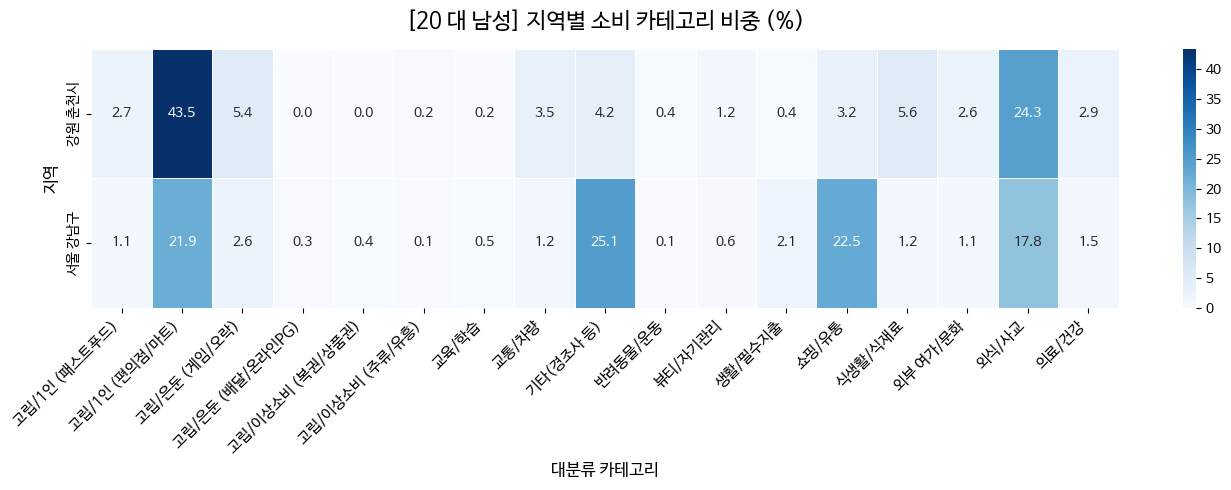

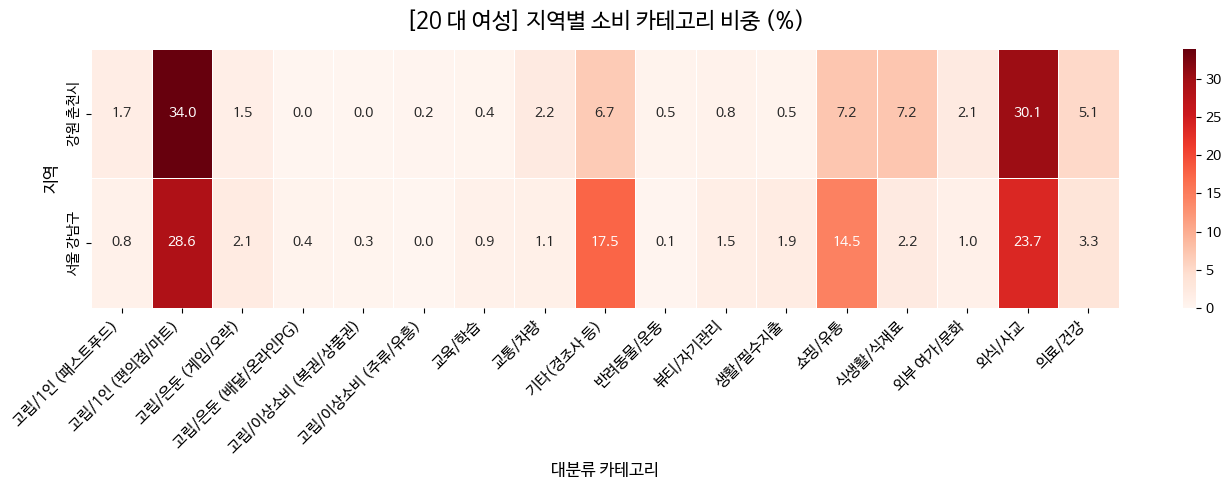

In [65]:
# 20대 남성, 20대 여성
plot_demographic_heatmap('20 대', '남성', 'Blues')
plot_demographic_heatmap('20 대', '여성', 'Reds')

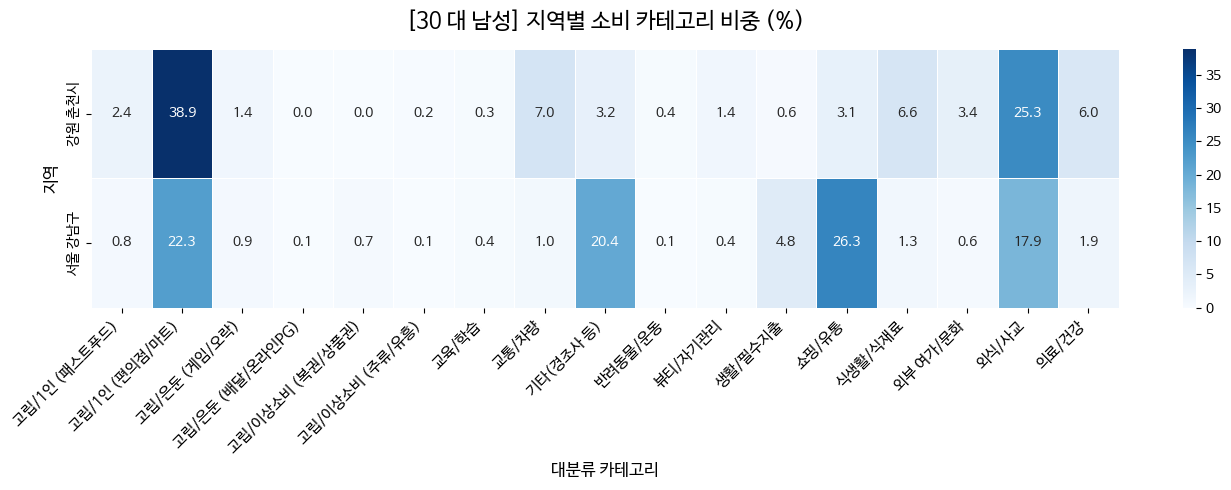

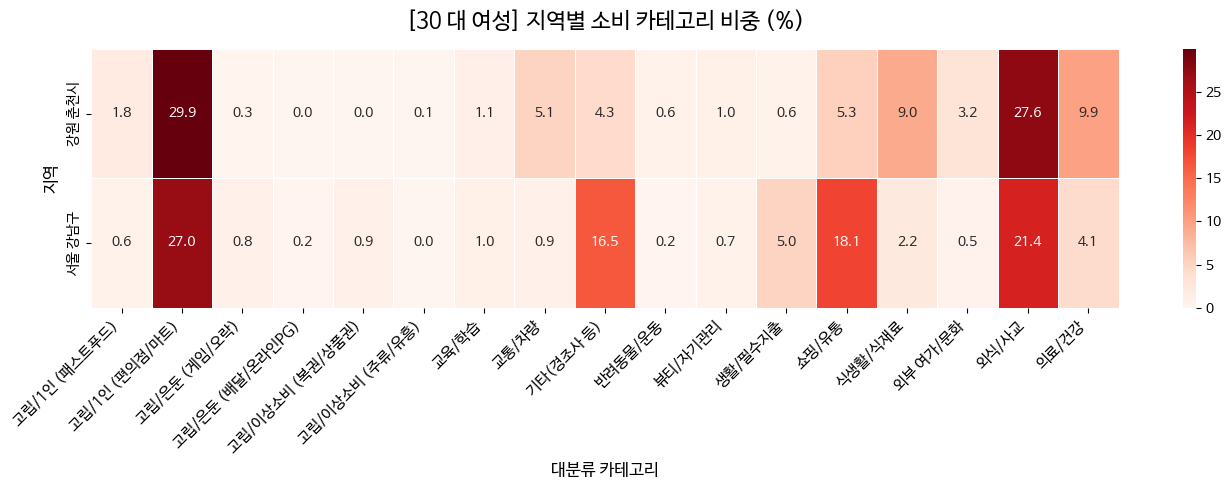

In [66]:
# 30대 남성, 30대 여성
plot_demographic_heatmap('30 대', '남성', 'Blues')
plot_demographic_heatmap('30 대', '여성', 'Reds')

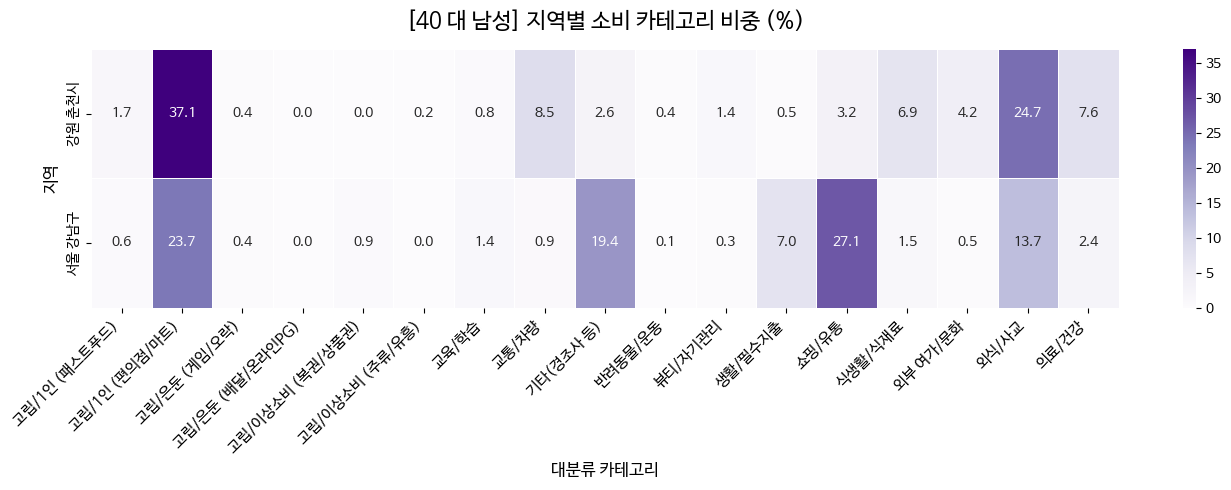

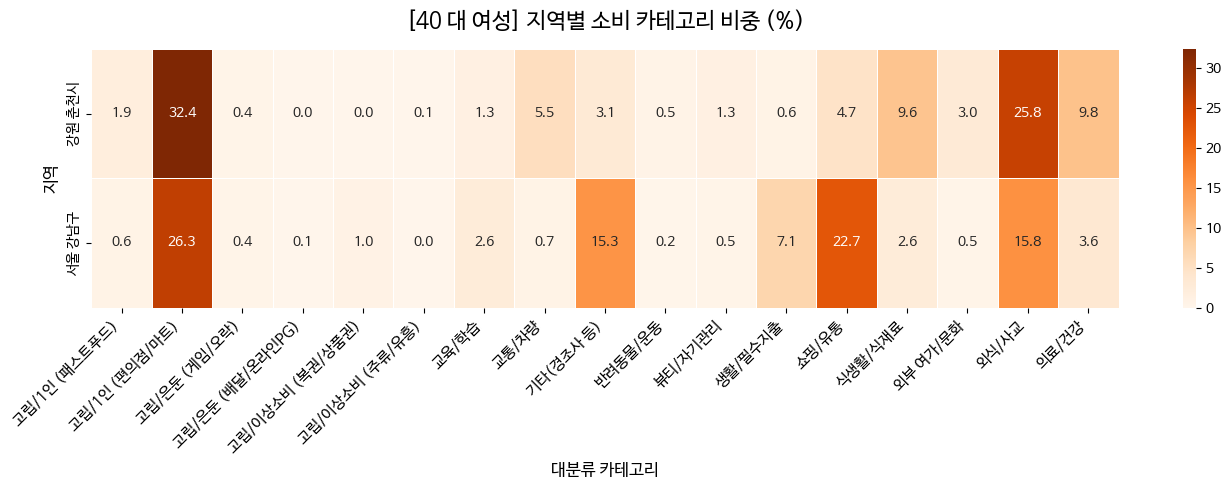

In [67]:
# 같은 방식으로 40대, 50대도 쉽게 호출할 수 있습니다.
plot_demographic_heatmap('40 대', '남성', 'Purples')
plot_demographic_heatmap('40 대', '여성', 'Oranges')

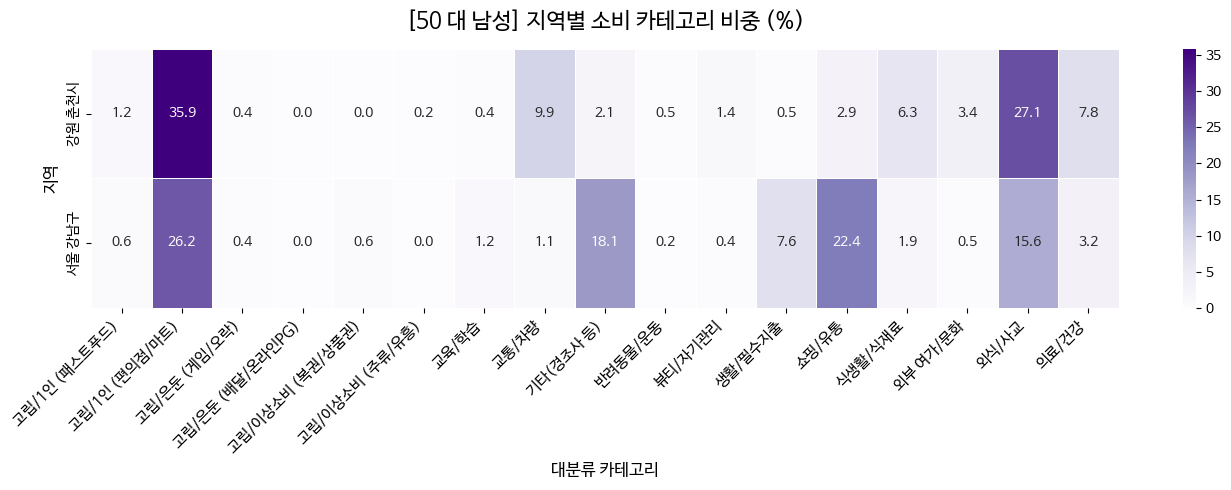

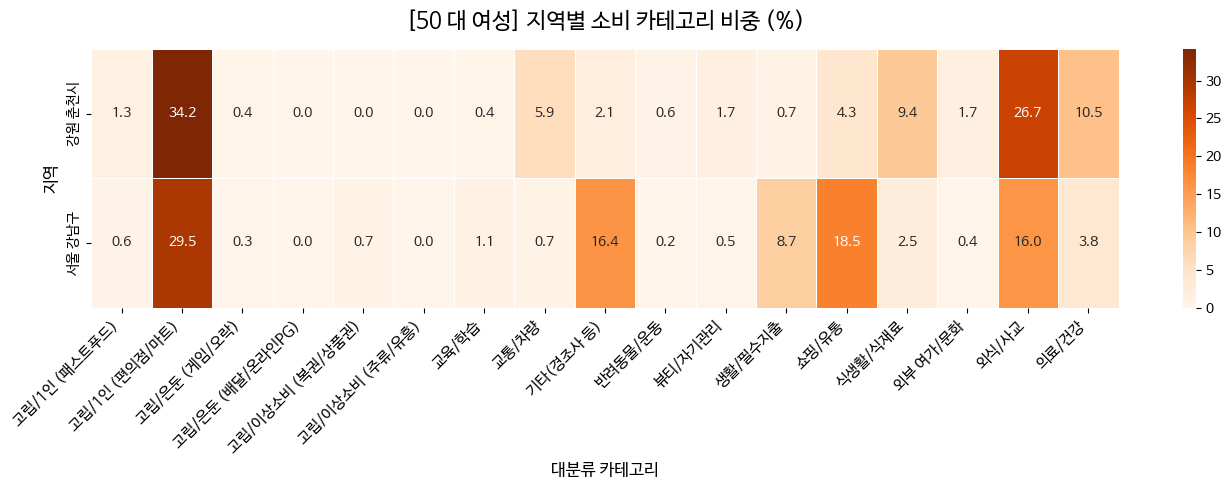

In [68]:
# 50대
plot_demographic_heatmap('50 대', '남성', 'Purples')
plot_demographic_heatmap('50 대', '여성', 'Oranges')

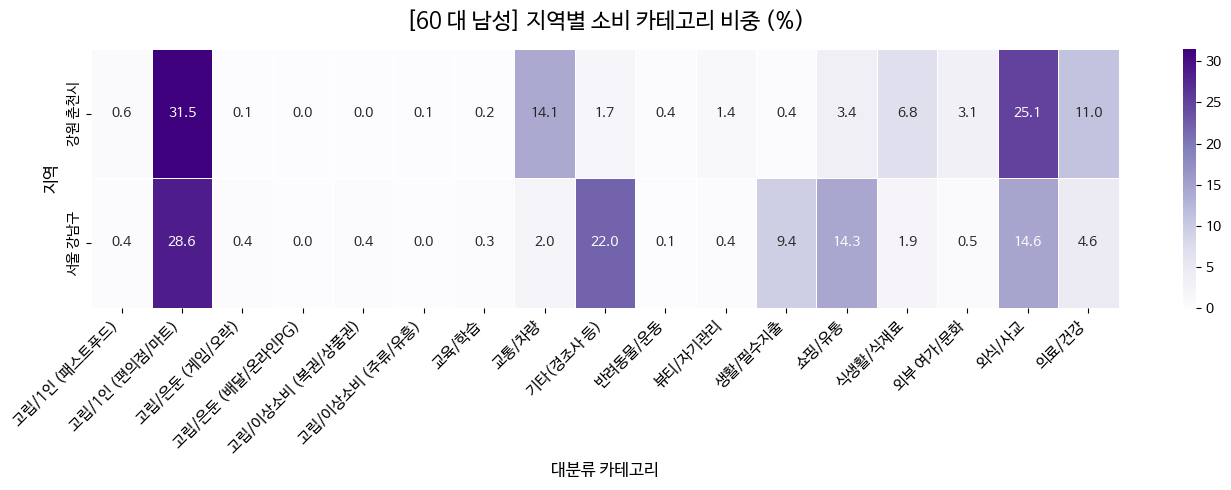

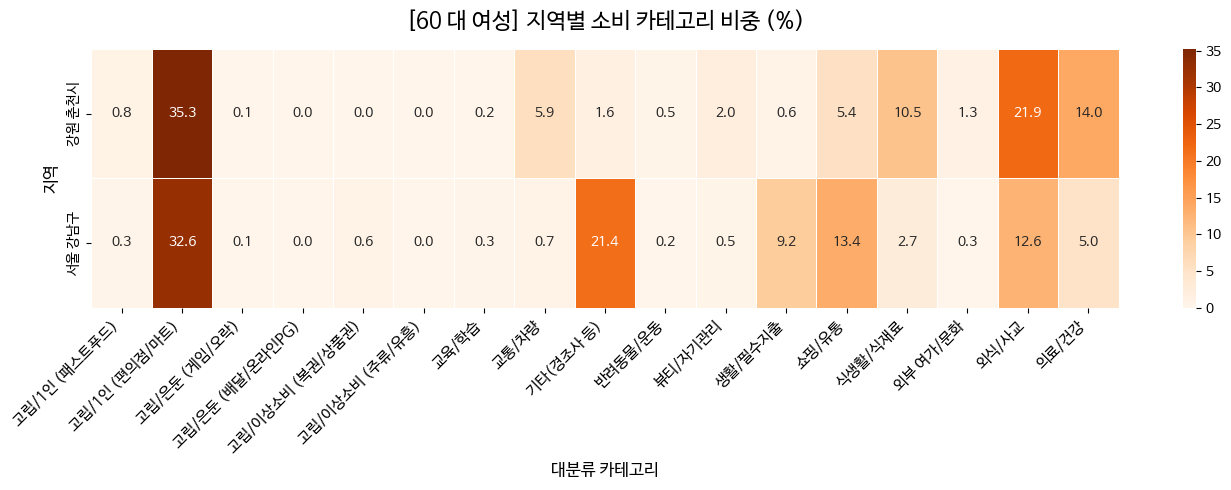

In [69]:
# 같은 방식으로 60대, 60대도 쉽게 호출할 수 있습니다.
plot_demographic_heatmap('60 대', '남성', 'Purples')
plot_demographic_heatmap('60 대', '여성', 'Oranges')